<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Box Plots**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize data composition and comparisons using box plots.


### Setup: Connecting to the Database


#### 1. Download the Database File


In [3]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Saving to: ‘survey-results-public.sqlite.1’

survey-results-publ 100%[===================>] 201.62M  6.29MB/s    in 31s     
2026-10-12 07:51:43 (6.54 MB/s) - ‘survey-results-public.sqlite.1’ saved [211415040/211415040]


#### 2. Connect to the Database


**Install the needed libraries**


In [4]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 158.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 164.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]


In [5]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 170.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 163.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 127.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]


In [6]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connect to the SQLite database
conn = sqlite3.connect('survey-results-public.sqlite')


## Demo: Basic SQL Queries


#### Demo 1: Count the Number of Rows in the Table


In [7]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)

   COUNT(*)
0     65437

#### Demo 2: List All Tables


In [8]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


#### Demo 3: Group Data by Age


In [9]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)

                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

## Visualizing Data


### Task 1: Visualizing the Distribution of Data


**1. Box Plot of `CompTotal` (Total Compensation)**


Use a box plot to analyze the distribution and outliers in total compensation.


Zero values left out of the plot: 127

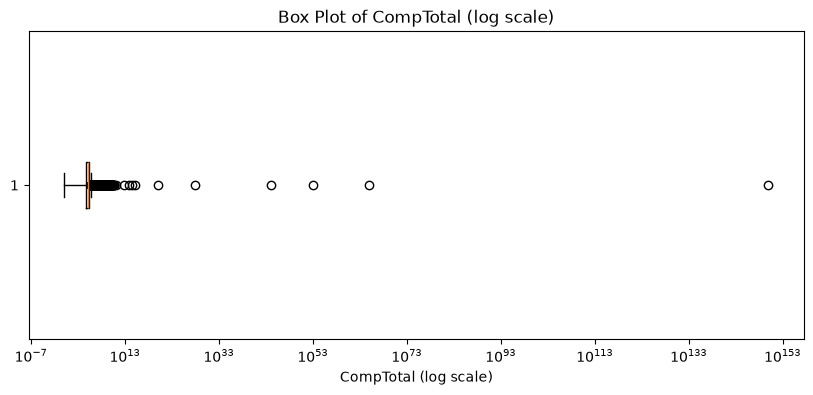

In [10]:
# your code goes here
# your code goes here
comp = pd.read_sql_query("SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL", conn)["CompTotal"]
print("Zero values left out of the plot:", (comp == 0).sum())

plt.figure(figsize=(10, 4))
plt.boxplot(comp[comp > 0], orientation="horizontal")
plt.xscale("log")
plt.title("Box Plot of CompTotal (log scale)")
plt.xlabel("CompTotal (log scale)")
plt.show()

**2. Box Plot of Age (converted to numeric values)**


Convert the `Age` column into numerical values and visualize the distribution.


count    65115.000000
mean        33.007871
std         11.264959
min         16.000000
25%         21.000000
50%         29.500000
75%         39.500000
max         70.000000
Name: Age_numeric, dtype: float64

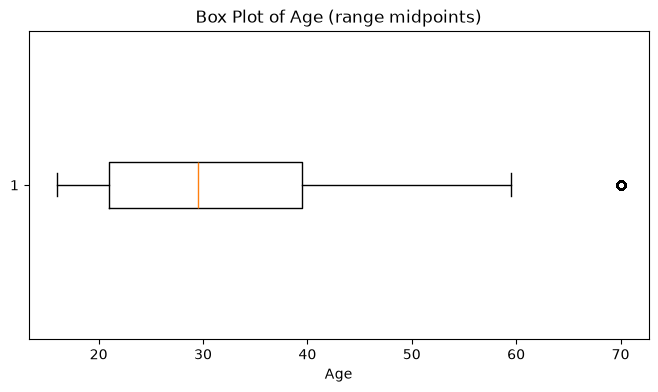

In [11]:
# your code goes here
# your code goes here
age_map = {
    "Under 18 years old": 16,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 70,
}

df_age = pd.read_sql_query("SELECT Age FROM main", conn)
df_age["Age_numeric"] = df_age["Age"].map(age_map)
print(df_age["Age_numeric"].describe())

plt.figure(figsize=(8, 4))
plt.boxplot(df_age["Age_numeric"].dropna(), orientation="horizontal")
plt.title("Box Plot of Age (range midpoints)")
plt.xlabel("Age")
plt.show()

### Task 2: Visualizing Relationships in Data


**1. Box Plot of `CompTotal` Grouped by Age Groups:**


Visualize the distribution of compensation across different age groups.


Age
Under 18 years old     19000.0
18-24 years old        60000.0
25-34 years old        98000.0
35-44 years old       118000.0
45-54 years old       130000.0
55-64 years old       133000.0
65 years or older     129642.5
Name: CompTotal, dtype: float64

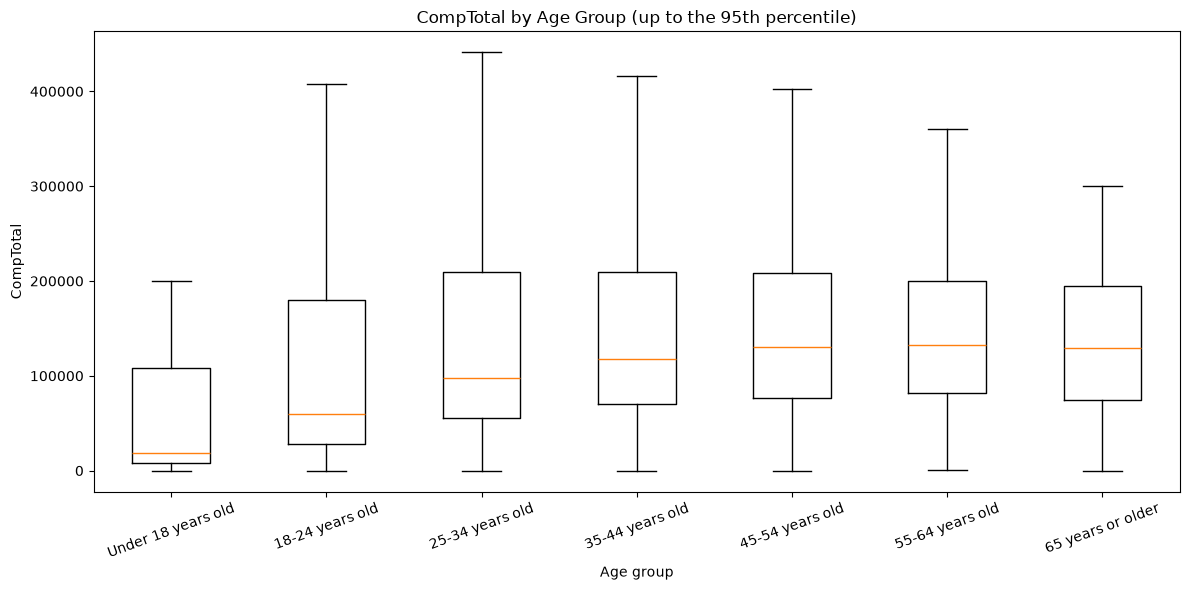

In [12]:
# your code goes here
# your code goes here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

df_ac = pd.read_sql_query("SELECT Age, CompTotal FROM main WHERE CompTotal IS NOT NULL", conn)
df_ac = df_ac[df_ac["Age"].isin(age_order)]
cap = df_ac["CompTotal"].quantile(0.95)
df_ac = df_ac[(df_ac["CompTotal"] > 0) & (df_ac["CompTotal"] <= cap)]
print(df_ac.groupby("Age")["CompTotal"].median().reindex(age_order))

data = [df_ac.loc[df_ac["Age"] == a, "CompTotal"] for a in age_order]
plt.figure(figsize=(12, 6))
plt.boxplot(data, tick_labels=age_order, showfliers=False)
plt.title("CompTotal by Age Group (up to the 95th percentile)")
plt.xlabel("Age group")
plt.ylabel("CompTotal")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**2. Box Plot of `CompTotal` Grouped by Job Satisfaction (`JobSatPoints_6`):**


Examine how compensation varies based on job satisfaction levels.


count    22478.000000
mean        24.940168
std         26.358629
min          0.000000
25%          5.000000
50%         20.000000
75%         30.000000
max        100.000000
Name: JobSatPoints_6, dtype: float64
              count    median
Satisfaction                 
0              4986  100000.0
1-20           8249  110000.0
21-40          4412  108500.0
41-60          1438  104500.0
61-100         2261  100000.0

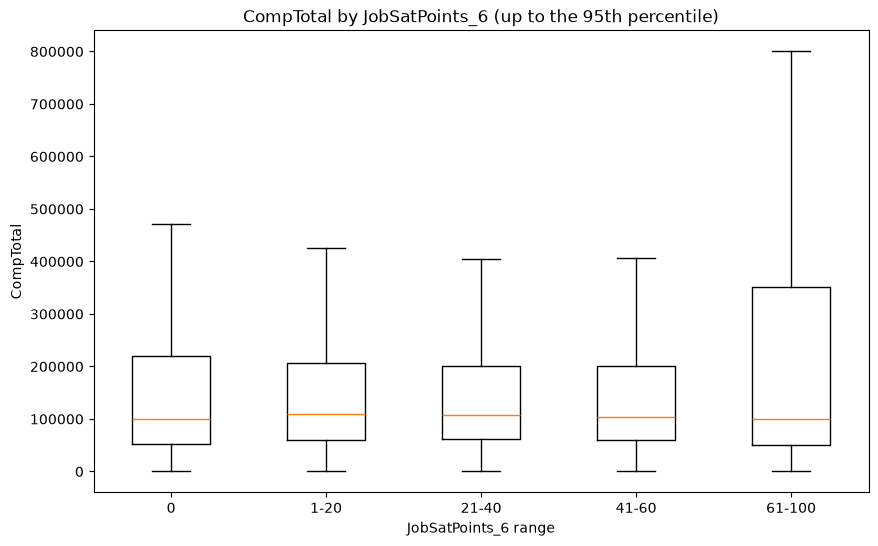

In [13]:
# your code goes here
# your code goes here
df_js = pd.read_sql_query(
    "SELECT JobSatPoints_6, CompTotal FROM main WHERE JobSatPoints_6 IS NOT NULL AND CompTotal IS NOT NULL", conn)
df_js["JobSatPoints_6"] = pd.to_numeric(df_js["JobSatPoints_6"], errors="coerce")
df_js = df_js.dropna(subset=["JobSatPoints_6"])
print(df_js["JobSatPoints_6"].describe())

cap = df_js["CompTotal"].quantile(0.95)
df_js = df_js[(df_js["CompTotal"] > 0) & (df_js["CompTotal"] <= cap)]

groups = ["0", "1-20", "21-40", "41-60", "61-100"]
df_js["Satisfaction"] = pd.cut(df_js["JobSatPoints_6"], bins=[-1, 0, 20, 40, 60, 100], labels=groups)
print(df_js.groupby("Satisfaction", observed=True)["CompTotal"].agg(["count", "median"]))

data = [df_js.loc[df_js["Satisfaction"] == g, "CompTotal"] for g in groups]
plt.figure(figsize=(10, 6))
plt.boxplot(data, tick_labels=groups, showfliers=False)
plt.title("CompTotal by JobSatPoints_6 (up to the 95th percentile)")
plt.xlabel("JobSatPoints_6 range")
plt.ylabel("CompTotal")
plt.show()

### Task 3: Visualizing the Composition of Data


**1. Box Plot of `ConvertedCompYearly` for the Top 5 Developer Types:**


Analyze compensation across the top 5 developer roles.


DevType
Developer, full-stack                            18260
Developer, back-end                               9928
Student                                           5102
Developer, front-end                              3349
Developer, desktop or enterprise applications     2493
Name: count, dtype: int64
DevType
Developer, full-stack                            60000.0
Developer, back-end                              64098.0
Student                                          15466.0
Developer, front-end                             48000.0
Developer, desktop or enterprise applications    60000.0
Name: ConvertedCompYearly, dtype: float64

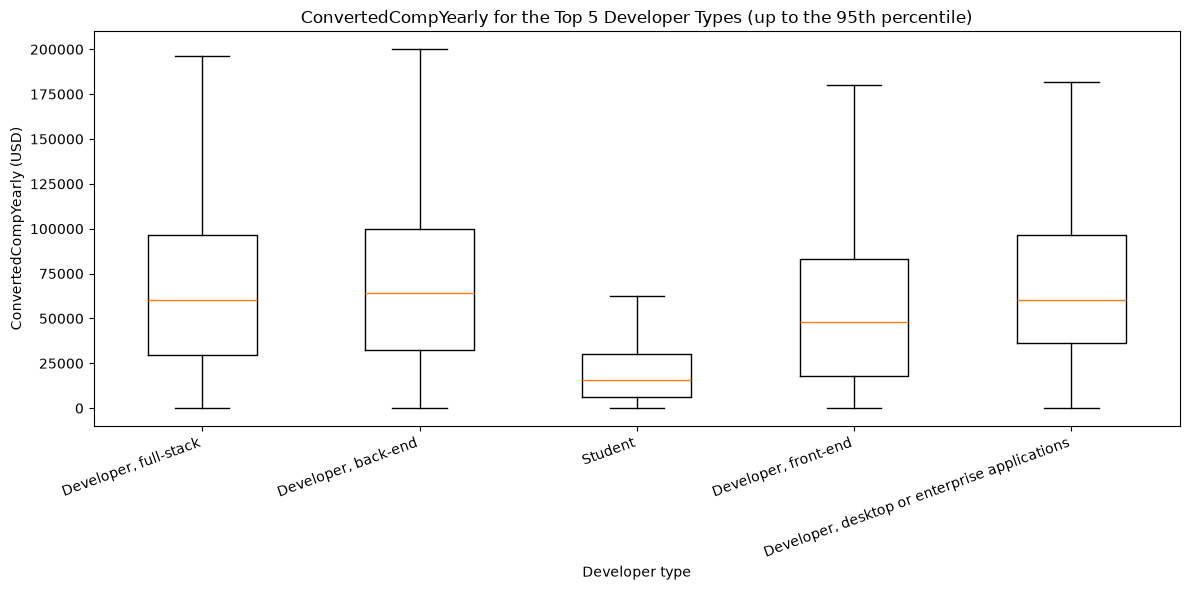

In [14]:
# your code goes here
# your code goes here
df_dev = pd.read_sql_query("SELECT DevType, ConvertedCompYearly FROM main WHERE DevType IS NOT NULL", conn)
df_dev["DevType"] = df_dev["DevType"].str.split(";")
df_dev = df_dev.explode("DevType")
df_dev["DevType"] = df_dev["DevType"].str.strip()

top5_dev = df_dev["DevType"].value_counts().head(5).index.tolist()
print(df_dev["DevType"].value_counts().head(5))

d = df_dev[df_dev["DevType"].isin(top5_dev)].dropna(subset=["ConvertedCompYearly"])
cap = d["ConvertedCompYearly"].quantile(0.95)
d = d[d["ConvertedCompYearly"] <= cap]
print(d.groupby("DevType")["ConvertedCompYearly"].median().reindex(top5_dev))

data = [d.loc[d["DevType"] == t, "ConvertedCompYearly"] for t in top5_dev]
plt.figure(figsize=(12, 6))
plt.boxplot(data, tick_labels=top5_dev, showfliers=False)
plt.title("ConvertedCompYearly for the Top 5 Developer Types (up to the 95th percentile)")
plt.xlabel("Developer type")
plt.ylabel("ConvertedCompYearly (USD)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**2. Box Plot of `CompTotal` for the Top 5 Countries:**


Analyze compensation across respondents from the top 5 countries.


Country
United States of America                                11095
Germany                                                  4947
India                                                    4231
United Kingdom of Great Britain and Northern Ireland     3224
Ukraine                                                  2672
Name: count, dtype: int64
Country
United States of America                                 148000.0
Germany                                                   69200.0
India                                                   1300000.0
United Kingdom of Great Britain and Northern Ireland      67740.5
Ukraine                                                   66000.0
Name: CompTotal, dtype: float64

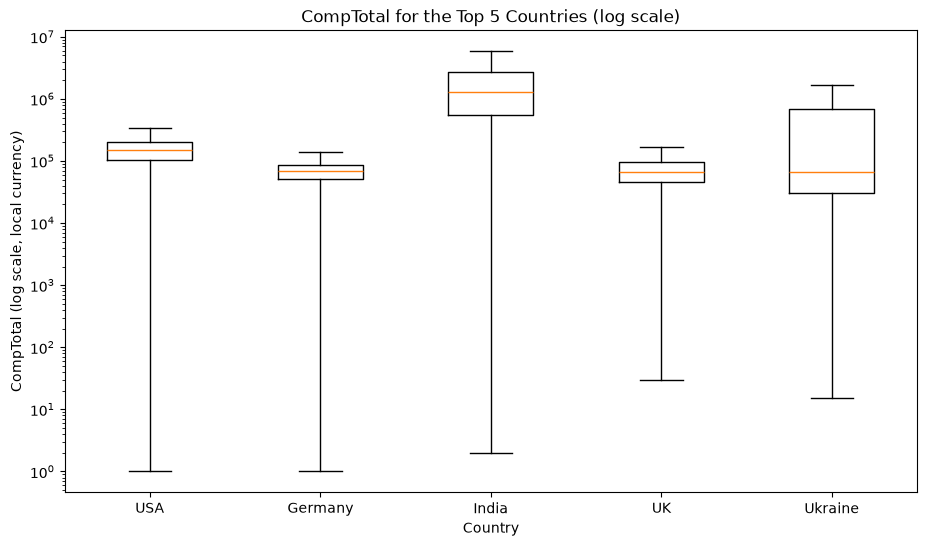

In [15]:
# your code goes here
# your code goes here
df_c = pd.read_sql_query("SELECT Country, CompTotal FROM main WHERE Country IS NOT NULL", conn)
top5_c = df_c["Country"].value_counts().head(5).index.tolist()
print(df_c["Country"].value_counts().head(5))

d = df_c[df_c["Country"].isin(top5_c)].dropna(subset=["CompTotal"])
d = d[d["CompTotal"] > 0]                 # zeros cannot be shown on a log scale
print(d.groupby("Country")["CompTotal"].median().reindex(top5_c))

short = {"United States of America": "USA",
         "United Kingdom of Great Britain and Northern Ireland": "UK"}
labels = [short.get(c, c) for c in top5_c]

data = [d.loc[d["Country"] == c, "CompTotal"] for c in top5_c]
plt.figure(figsize=(11, 6))
plt.boxplot(data, tick_labels=labels, showfliers=False)
plt.yscale("log")
plt.title("CompTotal for the Top 5 Countries (log scale)")
plt.xlabel("Country")
plt.ylabel("CompTotal (log scale, local currency)")
plt.show()

### Task 4: Visualizing Comparison of Data


**1. Box Plot of CompTotal Across Employment Types:**


Analyze compensation for different employment types.


Employment
Employed, full-time                                     29193
Independent contractor, freelancer, or self-employed     5740
Employed, part-time                                      1986
Student, full-time                                       1171
Student, part-time                                       1020
Name: count, dtype: int64
Employment
Employed, full-time                                     113400.0
Independent contractor, freelancer, or self-employed    120000.0
Employed, part-time                                      51330.0
Student, full-time                                       39000.0
Student, part-time                                       60000.0
Name: CompTotal, dtype: float64

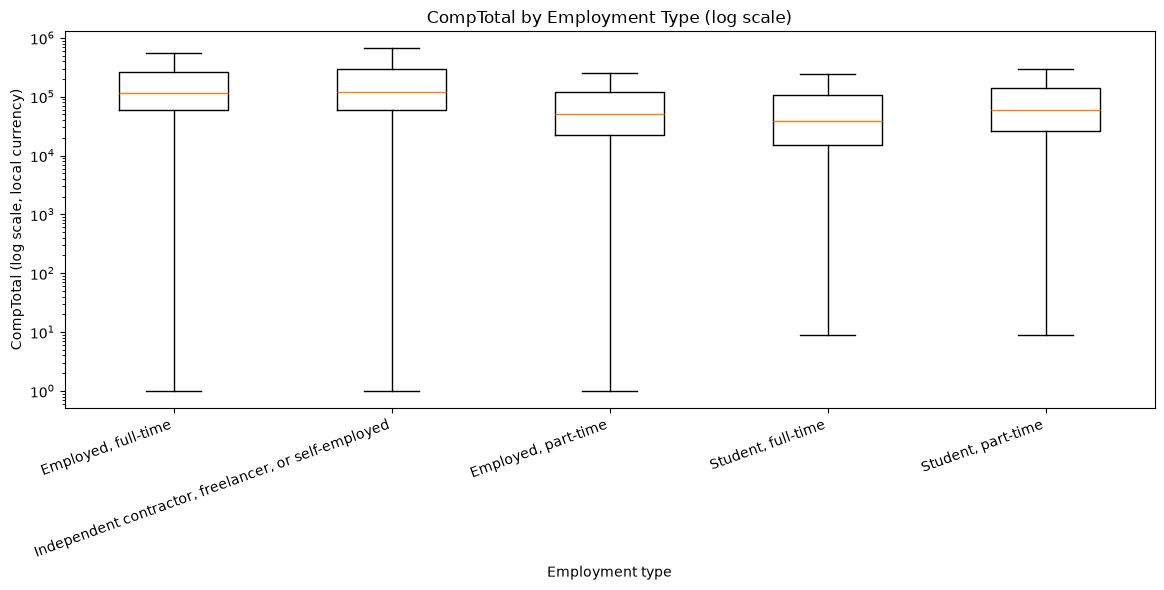

In [16]:
# your code goes here
# your code goes here
df_emp = pd.read_sql_query("SELECT Employment, CompTotal FROM main WHERE Employment IS NOT NULL AND CompTotal IS NOT NULL", conn)
df_emp["Employment"] = df_emp["Employment"].str.split(";")
df_emp = df_emp.explode("Employment")
df_emp["Employment"] = df_emp["Employment"].str.strip()
df_emp = df_emp[df_emp["CompTotal"] > 0]

top_emp = df_emp["Employment"].value_counts().head(5).index.tolist()
print(df_emp["Employment"].value_counts().head(5))
print(df_emp[df_emp["Employment"].isin(top_emp)].groupby("Employment")["CompTotal"].median().reindex(top_emp))

data = [df_emp.loc[df_emp["Employment"] == e, "CompTotal"] for e in top_emp]
plt.figure(figsize=(12, 6))
plt.boxplot(data, tick_labels=top_emp, showfliers=False)
plt.yscale("log")
plt.title("CompTotal by Employment Type (log scale)")
plt.xlabel("Employment type")
plt.ylabel("CompTotal (log scale, local currency)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**2. Box Plot of `YearsCodePro` by Job Satisfaction (`JobSatPoints_6`):**


Examine the distribution of professional coding years by job satisfaction levels.


              count  median   mean
Satisfaction                      
0              7503     7.0   9.22
1-20          10557     9.0  11.23
21-40          5367     9.0  11.31
41-60          1873     8.0  10.31
61-100         3319     6.0   7.94

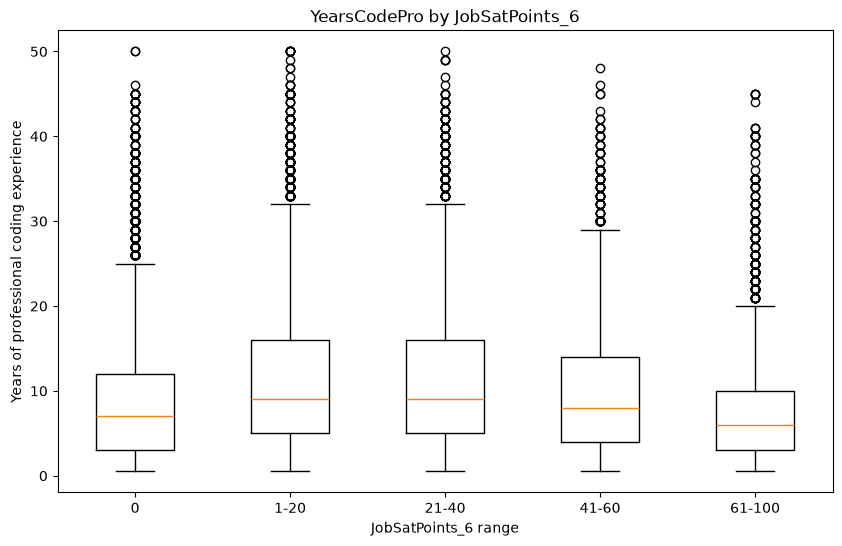

In [17]:
# your code goes here
# your code goes here
df_y = pd.read_sql_query(
    "SELECT YearsCodePro, JobSatPoints_6 FROM main WHERE YearsCodePro IS NOT NULL AND JobSatPoints_6 IS NOT NULL", conn)
df_y["Years"] = pd.to_numeric(
    df_y["YearsCodePro"].replace({"Less than 1 year": 0.5, "More than 50 years": 50}), errors="coerce")
df_y["JobSatPoints_6"] = pd.to_numeric(df_y["JobSatPoints_6"], errors="coerce")
df_y = df_y.dropna(subset=["Years", "JobSatPoints_6"])

groups = ["0", "1-20", "21-40", "41-60", "61-100"]
df_y["Satisfaction"] = pd.cut(df_y["JobSatPoints_6"], bins=[-1, 0, 20, 40, 60, 100], labels=groups)
print(df_y.groupby("Satisfaction", observed=True)["Years"].agg(["count", "median", "mean"]).round(2))

data = [df_y.loc[df_y["Satisfaction"] == g, "Years"] for g in groups]
plt.figure(figsize=(10, 6))
plt.boxplot(data, tick_labels=groups)
plt.title("YearsCodePro by JobSatPoints_6")
plt.xlabel("JobSatPoints_6 range")
plt.ylabel("Years of professional coding experience")
plt.show()

### Final Step: Close the Database Connection


After completing the lab, close the connection to the SQLite database:


In [18]:
conn.close()

## Summary


In this lab, you used box plots to visualize various aspects of the dataset, focusing on:

- Visualize distributions of compensation and age.

- Explore relationships between compensation, job satisfaction, and professional coding experience.

- Analyze data composition across developer roles and countries.

- Compare compensation across employment types and satisfaction levels.

Box plots provided clear insights into the spread, outliers, and central tendencies of various features in the dataset.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
